# 01 - Network validation

The IEEE 33-bus feeder (Baran & Wu, 1989) is loaded from pandapower's `case33bw`. Before any modification, the unmodified case is checked against the published reference (202.7 kW losses, minimum voltage 0.9131 pu at IEEE bus 18). Then the project network (substation transformer with OLTC, line ratings) is built and inspected.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.utils.config import load_config
from src.analysis import visualization as viz
viz.apply_style()
config = load_config(ROOT / "config" / "config.yaml")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

In [2]:
import pandapower as pp, pandapower.networks as pn
ref = pn.case33bw(); pp.runpp(ref)
print(f'Losses: {ref.res_line.pl_mw.sum()*1000:.1f} kW (published: 202.7 kW)')
print(f'Minimum voltage: {ref.res_bus.vm_pu.min():.4f} pu at IEEE bus {ref.res_bus.vm_pu.idxmin()+1} (published: 0.9131 pu, bus 18)')

Losses: 202.7 kW (published: 202.7 kW)

Minimum voltage: 0.9131 pu at IEEE bus 18 (published: 0.9131 pu, bus 18)

## Project network
Documented modifications: tie lines removed (radial), 110/12.66 kV transformer with OLTC, discrete line ratings sized for 60 % utilization at nominal peak, residential/commercial load labels.

In [3]:
from src.grid.network import build_network, run_power_flow
net = build_network(config)
print(net.trafo[['sn_mva','vn_hv_kv','vn_lv_kv','vk_percent','tap_step_percent','tap_min','tap_max']].T)
lines = net.line[['name','r_ohm_per_km','x_ohm_per_km','max_i_ka']].assign(rating_A=lambda d: d.max_i_ka*1000)
lines.head(10)

                       0
sn_mva              5.00
vn_hv_kv          110.00
vn_lv_kv           12.66
vk_percent          8.00
tap_step_percent    1.25
tap_min            -9.00
tap_max             9.00

,name,r_ohm_per_km,x_ohm_per_km,max_i_ka,rating_A
0,Line 1-2,0.0922,0.0470,0.40,400.0
1,Line 2-3,0.4930,0.2511,0.40,400.0
2,Line 3-4,0.3660,0.1864,0.30,300.0
3,Line 4-5,0.3811,0.1941,0.30,300.0
4,Line 5-6,0.8190,0.7070,0.30,300.0
5,Line 6-7,0.1872,0.6188,0.15,150.0
6,Line 7-8,0.7114,0.2351,0.15,150.0
7,Line 8-9,1.0300,0.7400,0.15,150.0
8,Line 9-10,1.0440,0.7400,0.15,150.0
9,Line 10-11,0.1966,0.0650,0.15,150.0


In [4]:
print(lines.rating_A.value_counts().rename('number of lines'))
net.load.groupby('profile').p_mw.agg(['count','sum'])

rating_A
150.0    27
300.0     3
400.0     2
Name: number of lines, dtype: int64

,count,sum
profile,,
commercial,7,1.800
residential,25,1.915


OLTC tap -4, MV busbar 1.0085 pu

Min voltage 0.9225 pu, transformer 96.3 %, max line 52.1 %

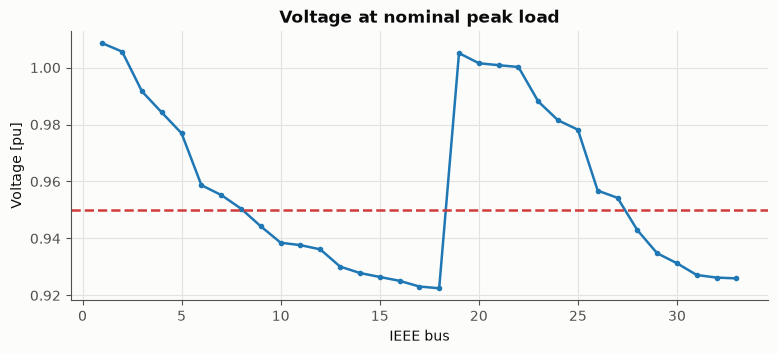

In [5]:
run_power_flow(net)  # all loads at nominal (non-coincident) peak
print(f'OLTC tap {net.trafo.tap_pos.iloc[0]:.0f}, MV busbar {net.res_bus.vm_pu[0]:.4f} pu')
print(f'Min voltage {net.res_bus.vm_pu.min():.4f} pu, transformer {net.res_trafo.loading_percent.iloc[0]:.1f} %, max line {net.res_line.loading_percent.max():.1f} %')
mv = net.res_bus.vm_pu[net.bus.vn_kv < 20]
fig, ax = plt.subplots(figsize=(9,3.5)); ax.plot(mv.index+1, mv.values, marker='o', markersize=3)
ax.axhline(config['limits']['v_min_pu'], color=viz.LIMIT, ls='--'); ax.set(xlabel='IEEE bus', ylabel='Voltage [pu]', title='Voltage at nominal peak load'); plt.show()